# Taller 1 — Notebook 01: Entendimiento inicial de los datos

**MINE-4101 · Ciencia de Datos Aplicada** · Supervisión de contratación pública de bienes

Este notebook cubre el **punto 1 (20 %)** del taller: dimensiones y tipos del dataset,
análisis univariado de los cinco atributos más importantes, e identificación y tratamiento
de los problemas de calidad.

Además resuelve una pregunta que condiciona todo lo que viene después: **¿cuáles de las
desviaciones que define el enunciado son realmente medibles con estos datos?** La respuesta
resultó ser que ninguna de las tres lo es en su forma literal, y eso obligó a redefinir la
variable objetivo. El bloque F documenta esa decisión con evidencia.

## Orden de ejecución

Este es el **primer** notebook y debe correr antes que los demás: produce
`data/processed/contratos_limpio.parquet`, del que dependen los notebooks 02, 03 y 04.

## Estructura

| Bloque | Contenido |
|---|---|
| A | Inventario estructural: dimensiones, tipos, memoria |
| B | Perfilado sistemático de las 36 columnas |
| C | Batería de 21 reglas de integridad |
| D | Completitud real frente a aparente |
| E | Estabilidad temporal, anomalías de fecha por periodo y sensibilidad sin 2019 o sin 2025 |
| F | **Viabilidad de las señales objetivo** (bloque decisivo) |
| G | Top 5 atributos: análisis univariado |
| H | Pipeline de tratamiento y bitácora de decisiones |
| I | Artefactos generados |

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# El notebook se puede ejecutar desde notebooks/ o desde la raiz del repo.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import config
from src.carga import cargar_crudo
from src.limpieza import limpiar
from src.perfilado import perfil_completo, resumen_perfil
from src.viz import aplicar_estilo, guardar, pesos_cortos

warnings.filterwarnings("ignore", category=FutureWarning)
aplicar_estilo()
config.asegurar_directorios()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)

print(f"raiz del proyecto : {RAIZ}")
print(f"fecha de corte    : {config.FECHA_CORTE}")
print(f"ventana plausible : [{config.ANIO_MIN_PLAUSIBLE}, {config.ANIO_MAX_PLAUSIBLE}]")

raiz del proyecto : C:\Repositorios\Ciencia Aplicada de DAtos\Taller 1\cda_taller_1
fecha de corte    : 2026-09-23
ventana plausible : [2010, 2031]


---
## Bloque A — Inventario estructural

Se lee el parquet **sin transformarlo**. El `sha256` deja constancia de sobre qué bytes
exactos se corrió este perfilado, para que los resultados sean reproducibles y auditables.

In [2]:
df_crudo, meta = cargar_crudo()

print(f"archivo   : {meta['archivo']}")
print(f"sha256    : {meta['sha256']}")
print(f"tamano    : {meta['bytes'] / 1024**2:.1f} MB en disco")
print(f"dimension : {meta['filas']:,} filas x {meta['columnas']} columnas")
print(f"memoria   : {meta['memoria_mb']} MB en pandas")
print(f"escrito por: {meta['creado_por']}")

  leyendo secop_bienes.parquet ...


  cargado: 196,391 filas x 36 columnas (400.0 MB en memoria)


archivo   : secop_bienes.parquet
sha256    : 3eb495b1d7fda28e28863ed57f18e59a4aa611b565c77df6b9790951e1bcb0d2
tamano    : 30.3 MB en disco
dimension : 196,391 filas x 36 columnas
memoria   : 400.0 MB en pandas
escrito por: parquet-cpp-arrow version 25.0.1


In [3]:
# Composicion por tipo de dato: el dataset es abrumadoramente categorico.
tipos = (df_crudo.dtypes.astype(str).value_counts()
         .rename_axis("dtype").reset_index(name="n_columnas"))
tipos["columnas"] = tipos["dtype"].map(
    lambda t: ", ".join(df_crudo.columns[df_crudo.dtypes.astype(str) == t][:6]) + " ...")
display(tipos)

print("Solo 5 columnas numericas y 3 de fecha: las 28 restantes son texto.")
print("Eso define la estrategia: el analisis sera mayoritariamente de tablas de")
print("contingencia y pruebas sobre proporciones, no de correlaciones continuas.")

,dtype,n_columnas,columnas
0,object,28,"id_contrato, nombre_entidad, departamento, ciu..."
1,int64,4,"valor_pagado, valor_facturado, valor_pendiente..."
2,datetime64[us],3,"fecha_de_firma, fecha_de_inicio_del_contrato, ..."
3,float64,1,valor_del_contrato ...


Solo 5 columnas numericas y 3 de fecha: las 28 restantes son texto.
Eso define la estrategia: el analisis sera mayoritariamente de tablas de
contingencia y pruebas sobre proporciones, no de correlaciones continuas.


In [4]:
df_crudo.head(3).T

,0,1,2
id_contrato,CO1.PCCNTR.1000001,CO1.PCCNTR.1000507,CO1.PCCNTR.1000901
nombre_entidad,PARQUES NACIONALES NATURALES DE COLOMBIA - DIR...,AGENCIA LOGISTICA DE LAS FUERZAS MILITARES,FUERZA AEROESPACIAL COLOMBIANA
departamento,Distrito Capital de Bogotá,Distrito Capital de Bogotá,Distrito Capital de Bogotá
ciudad,No Definido,Bogotá,Bogotá
orden,Territorial,Nacional,Nacional
sector,Ambiente y Desarrollo Sostenible,defensa,defensa
rama,Ejecutivo,Ejecutivo,Ejecutivo
entidad_centralizada,Centralizada,Centralizada,Centralizada
tipo_de_contrato,Suministros,Suministros,Compraventa
modalidad_de_contratacion,Mínima cuantía,Selección Abreviada de Menor Cuantía,Mínima cuantía


---
## Bloque B — Perfilado sistemático de las 36 columnas

En lugar de mirar solo los atributos de interés, se barren **todas** las columnas. El
perfilado calcula por cada una: completitud aparente y efectiva, cardinalidad, moda,
entropía normalizada y muestras de los valores centinela encontrados.

La distinción entre completitud **aparente** (lo que dice `isna()`) y **efectiva** (lo que
queda tras reconocer los centinelas de texto) es el hallazgo central del bloque.

In [5]:
perfil = perfil_completo(df_crudo, meta)
resumen_perfil(perfil).T.rename(columns={0: "valor"})

  A/B  estructura y completitud real vs aparente ...


  C    unicidad y duplicados ...


  D    validez y dominios ...


  G    temporalidad y parseo de duracion ...


  E    reglas de negocio ...


  F    outliers y exactitud ...


  I    texto libre ...

  H    relevancia de variables ...


  J    indice de calidad ...


       preparando datos de graficos ...


,valor
filas,196391
columnas,36
indice_calidad,75.99
nivel,Aceptable con reservas
completitud_aparente_media,99.97
completitud_efectiva_media,97.04
reglas_evaluadas,21
reglas_incumplidas,18


In [6]:
cols = pd.DataFrame(perfil["columnas"])
tabla_perfil = cols[[
    "id", "columna", "rol", "dtype", "cardinalidad", "n_null", "n_sentinela",
    "completitud_aparente", "completitud_efectiva", "brecha_completitud",
    "moda", "pct_moda", "entropia_norm",
]]
tabla_perfil.to_csv(config.TABLAS / "perfilado_columnas.csv", index=False, encoding="utf-8")
print(f"escrito: reports/tablas/perfilado_columnas.csv ({len(tabla_perfil)} filas)")
tabla_perfil

escrito: reports/tablas/perfilado_columnas.csv (36 filas)


,id,columna,rol,dtype,cardinalidad,n_null,n_sentinela,completitud_aparente,completitud_efectiva,brecha_completitud,moda,pct_moda,entropia_norm
0,V01,id_contrato,Identificador,object,196391,0,0,100.0000,100.0000,0.0000,CO1.PCCNTR.999902,0.001,1.0000
1,V02,nombre_entidad,Dimensión,object,3452,0,0,100.0000,100.0000,0.0000,AGENCIA LOGISTICA DE LAS FUERZAS MILITARES,1.739,0.8756
2,V03,departamento,Dimensión,object,33,0,7510,100.0000,96.1760,3.8240,Distrito Capital de Bogotá,27.688,0.7944
3,V04,ciudad,Dimensión,object,675,0,41672,100.0000,78.7811,21.2189,Bogotá,21.507,0.6960
4,V05,orden,Dimensión,object,3,0,9,100.0000,99.9954,0.0046,Territorial,49.543,0.6834
5,V06,sector,Dimensión,object,24,0,24474,100.0000,87.5381,12.4619,Servicio Público,21.749,0.7346
6,V07,rama,Dimensión,object,4,0,9,100.0000,99.9954,0.0046,Ejecutivo,80.132,0.4612
7,V08,entidad_centralizada,Dimensión,object,2,0,0,100.0000,100.0000,0.0000,Centralizada,79.515,0.7315
8,V09,tipo_de_contrato,Dimensión,object,2,0,0,100.0000,100.0000,0.0000,Suministros,54.296,0.9947
9,V10,modalidad_de_contratacion,Dimensión,object,9,0,0,100.0000,100.0000,0.0000,Mínima cuantía,59.958,0.5981


In [7]:
# Las cinco variables numericas, con percentiles extremos que revelan la cola.
pcts = [0, 0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999, 1.0]
num = df_crudo[config.COLS_NUMERICAS].quantile(pcts).T
num.columns = [f"p{p*100:g}" for p in pcts]
num["ceros"] = (df_crudo[config.COLS_NUMERICAS] == 0).sum()
num["negativos"] = (df_crudo[config.COLS_NUMERICAS] < 0).sum()
num["asimetria"] = df_crudo[config.COLS_NUMERICAS].skew()
display(num.round(2))

v_num = df_crudo["valor_del_contrato"]
ordenes = np.log10(v_num.max() / v_num.median())
ceros_adic = 100 * (df_crudo["dias_adicionados"] == 0).mean()
print(f"valor_del_contrato: el p100 es {ordenes:.1f} ordenes de magnitud mayor que la mediana.")
print(f"dias_adicionados  : el {ceros_adic:.1f} % vale 0, es decir la variable es cero en su "
      "gran mayoria.")

,p0,p0.1,p1,p5,p25,p50,p75,p95,p99,p99.9,p100,ceros,negativos,asimetria
valor_del_contrato,0.0,0.97,701068.0,2309772.5,12021214.0,33600000.0,100000000.0,800000000.0,4.118482e+09,3.095914e+10,1.285845e+16,188,0,443.16
valor_pagado,0.0,0.00,0.0,0.0,0.0,0.0,28120772.5,312000000.0,1.714289e+09,1.239780e+10,5.944034e+11,107639,0,168.35
valor_facturado,0.0,0.00,0.0,0.0,0.0,3207328.0,37086225.0,384295956.0,2.025785e+09,1.461152e+10,5.945032e+11,91825,0,137.70
valor_pendiente_de_pago,-84184884.0,0.00,0.0,0.0,0.0,6717571.0,42411892.0,447371878.5,2.612250e+09,2.137724e+10,1.285845e+16,57633,144,443.16
dias_adicionados,0.0,0.00,0.0,0.0,0.0,0.0,0.0,30.0,1.220000e+02,3.160000e+02,1.427600e+04,177720,0,222.19


valor_del_contrato: el p100 es 8.6 ordenes de magnitud mayor que la mediana.


dias_adicionados  : el 90.5 % vale 0, es decir la variable es cero en su gran mayoria.


In [8]:
# Rango real de las fechas, incluidos los valores imposibles.
fechas = pd.DataFrame({
    "min": df_crudo[config.COLS_FECHA].min(),
    "max": df_crudo[config.COLS_FECHA].max(),
    "nulos": df_crudo[config.COLS_FECHA].isna().sum(),
})
for c in config.COLS_FECHA:
    a = df_crudo[c].dt.year
    fechas.loc[c, "fuera_de_rango"] = int(
        (df_crudo[c].notna()
         & ~a.between(config.ANIO_MIN_PLAUSIBLE, config.ANIO_MAX_PLAUSIBLE)).sum())
display(fechas)

print("fecha_de_fin_del_contrato declara CERO nulos y aun asi llega al anio 202 d.C.")
print("fecha_de_firma es la unica sin nulos ni valores imposibles: sera el ancla temporal.")

,min,max,nulos,fuera_de_rango
fecha_de_firma,2019-01-01,2025-12-31,0,0.0
fecha_de_inicio_del_contrato,2016-06-27,2026-12-16,2440,0.0
fecha_de_fin_del_contrato,202-12-31,2065-01-31,0,20.0


fecha_de_fin_del_contrato declara CERO nulos y aun asi llega al anio 202 d.C.
fecha_de_firma es la unica sin nulos ni valores imposibles: sera el ancla temporal.


---
## Bloque C — Batería de reglas de integridad

21 reglas de negocio, agrupadas en unicidad, montos, plazos, fechas, coherencia lógica y
consistencia de entidades. Cada una reporta cuántos registros la violan.

In [9]:
reglas = pd.DataFrame(perfil["reglas"])[
    ["id", "regla", "severidad", "violaciones", "pct", "cumple"]]
reglas.to_csv(config.TABLAS / "chequeos_integridad.csv", index=False, encoding="utf-8")
print(f"escrito: reports/tablas/chequeos_integridad.csv")
print(f"reglas evaluadas: {len(reglas)} | incumplidas: {(~reglas['cumple']).sum()}")
reglas.sort_values("violaciones", ascending=False)

escrito: reports/tablas/chequeos_integridad.csv
reglas evaluadas: 21 | incumplidas: 18


,id,regla,severidad,violaciones,pct,cumple
9,R10,duración declarada ~= fecha_fin - fecha_inicio...,Media,50535,25.7318,False
12,R13,estado 'cerrado' implica valor_pendiente_de_pa...,Media,25782,13.1279,False
20,R22,duración del contrato es parseable a un número...,Alta,20819,10.6008,False
13,R14,dias_adicionados > 0 implica el_contrato_puede...,Baja,13726,6.9891,False
6,R07,fecha_de_firma <= fecha_de_inicio_del_contrato,Alta,13047,6.6434,False
15,R16,documento_proveedor y proveedor_adjudicado son...,Media,5332,2.7150,False
16,R18,codigo_de_categoria_principal cumple el patrón...,Media,4779,2.4334,False
3,R04,valor_facturado <= valor_del_contrato,Alta,214,0.1090,False
18,R20,valor_del_contrato > 0,Alta,188,0.0957,False
2,R03,valor_pagado <= valor_del_contrato,Alta,177,0.0901,False


figura: reports/figures/c_reglas_integridad.png


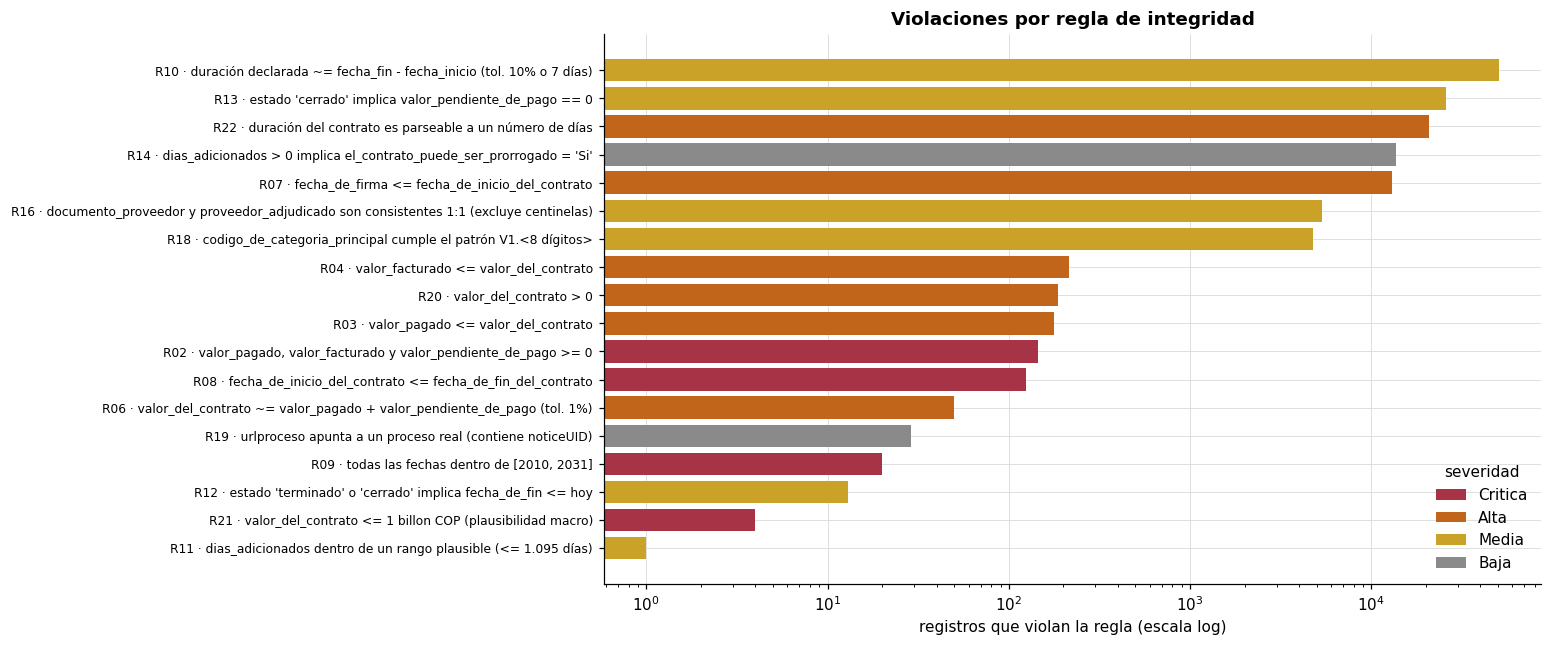

In [10]:
from matplotlib.patches import Patch
from src.viz import COLOR_SEVERIDAD, ORDEN_SEVERIDAD

r = reglas[reglas["violaciones"] > 0].sort_values("violaciones")
colores = [COLOR_SEVERIDAD.get(s, "#8a8a8a") for s in r["severidad"]]

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh(r["id"] + " · " + r["regla"], r["violaciones"], color=colores)
ax.set_xscale("log")
ax.set_xlabel("registros que violan la regla (escala log)")
ax.set_title("Violaciones por regla de integridad")
ax.tick_params(axis="y", labelsize=8)

# La leyenda se construye con parches: un barh sobre datos vacios no conserva
# el color y saldria con el del ciclo por defecto.
presentes = [s for s in ORDEN_SEVERIDAD if s in set(r["severidad"])]
ax.legend(handles=[Patch(facecolor=COLOR_SEVERIDAD[s], label=s) for s in presentes],
          title="severidad", loc="lower right")
print("figura:", guardar(fig, "c_reglas_integridad"))
plt.show()

### La regla que se retiró: ciudad y departamento

Una versión anterior de la batería incluía la regla **R17**, «cada ciudad pertenece a un único
departamento». La celda siguiente reproduce lo que marcaba. Ninguna de las ciudades que la violan
es un error de dato: son homónimos legítimos de la geografía colombiana. Armenia es la capital del
Quindío y también un municipio de Antioquia; La Unión existe en Valle, Antioquia, Nariño y Sucre.
La regla penalizaba la consistencia sin que hubiera suciedad detrás, así que se retiró.

Lo que sí queda es un hecho de estructura: **`ciudad` no es una llave**. Cualquier agregación
geográfica debe usar el par (departamento, ciudad), nunca la ciudad sola.

In [11]:
# R17 (retirada): ciudades cuyo nombre aparece en mas de un departamento.
# Se excluyen los centinelas, como en R16: un 'No Definido' no es una ciudad.
geo = df_crudo[(df_crudo["ciudad"] != "No Definido") & (df_crudo["departamento"] != "No Definido")]
en_varios = geo.groupby("ciudad")["departamento"].nunique()
en_varios = en_varios[en_varios > 1].sort_values(ascending=False)
marcadas = df_crudo["ciudad"].isin(en_varios.index)
print(f"ciudades cuyo nombre aparece en más de un departamento: {len(en_varios)}")
print(f"filas que marcaba la regla: {marcadas.sum():,} ({100 * marcadas.mean():.2f} %)")
print(f"las de más departamentos: {', '.join(f'{c} ({n})' for c, n in en_varios.head(6).items())}")
print(f"nombres de ciudad distintos: {geo['ciudad'].nunique()} · pares (departamento, ciudad): "
      f"{len(geo[['departamento', 'ciudad']].drop_duplicates())}")

ciudades cuyo nombre aparece en más de un departamento: 35
filas que marcaba la regla: 7,342 (3.74 %)
las de más departamentos: La Unión (4), Granada (3), San Pedro (3), Sucre (3), San Andrés (3), Albán (2)
nombres de ciudad distintos: 675 · pares (departamento, ciudad): 716


---
## Bloque D — Completitud real frente a aparente

Aquí está el problema de calidad más peligroso del dataset, porque es invisible: 34 de las
36 columnas reportan **cero nulos**, pero los faltantes vienen codificados como texto
(`No Definido`, `No aplica`, `UNSPECIFIED`, `xxxx`). Un `df.info()` da una sensación de
completitud que no existe.

In [12]:
ap = cols["completitud_aparente"].mean()
ef = cols["completitud_efectiva"].mean()
print(f"completitud aparente media : {ap:.2f} %")
print(f"completitud efectiva media : {ef:.2f} %")
print(f"brecha                     : {ap - ef:.2f} puntos porcentuales")
print(f"centinelas totales         : {cols['n_sentinela'].sum():,} celdas")
print(f"columnas con centinelas    : {(cols['n_sentinela'] > 0).sum()} de {len(cols)}")

peores = cols.nsmallest(10, "completitud_efectiva")[
    ["columna", "completitud_aparente", "completitud_efectiva",
     "brecha_completitud", "n_sentinela", "muestras_sentinela"]]
display(peores)

completitud aparente media : 99.97 %
completitud efectiva media : 97.04 %
brecha                     : 2.93 puntos porcentuales
centinelas totales         : 206,821 celdas
columnas con centinelas    : 15 de 36


,columna,completitud_aparente,completitud_efectiva,brecha_completitud,n_sentinela,muestras_sentinela
16,condiciones_de_entrega,100.0000,74.5554,25.4446,49971,{'No Definido': 49971}
3,ciudad,100.0000,78.7811,21.2189,41672,{'No Definido': 41672}
21,g_nero_representante_legal,100.0000,81.7599,18.2401,35822,{'No Definido': 35822}
28,habilita_pago_adelantado,100.0000,85.4846,14.5154,28507,{'No Definido': 28507}
5,sector,100.0000,87.5381,12.4619,24474,"{'No aplica/No pertenece': 24465, 'No Definido..."
15,duraci_n_del_contrato,100.0000,95.1678,4.8322,9490,{'No definido': 9490}
2,departamento,100.0000,96.1760,3.8240,7510,{'No Definido': 7510}
10,codigo_de_categoria_principal,100.0000,97.5666,2.4334,4779,{'UNSPECIFIED': 4779}
13,fecha_de_inicio_del_contrato,98.7576,98.7576,0.0000,0,{}
18,documento_proveedor,99.9980,99.2006,0.7974,1566,"{'No Definido': 1563, 'no aplica': 2, 'xxxx': 1}"


figura:

 reports/figures/d_completitud_aparente_vs_efectiva.png


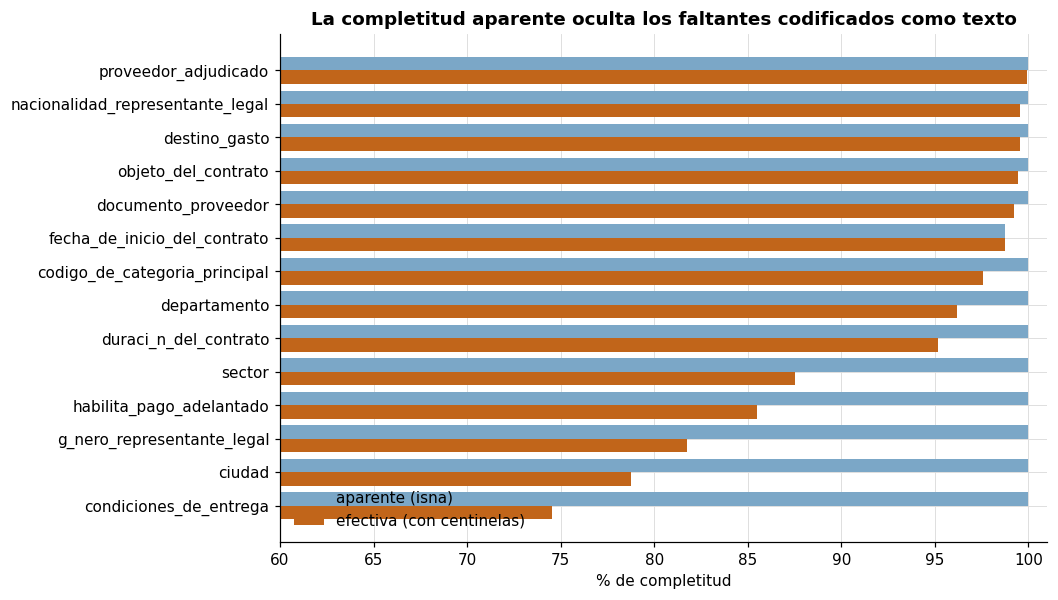

In [13]:
p = cols.nsmallest(14, "completitud_efectiva").sort_values("completitud_efectiva")
y = np.arange(len(p))
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(y + 0.2, p["completitud_aparente"], height=0.4,
        color="#7ba7c7", label="aparente (isna)")
ax.barh(y - 0.2, p["completitud_efectiva"], height=0.4,
        color="#c1651a", label="efectiva (con centinelas)")
ax.set_yticks(y, p["columna"])
ax.set_xlim(60, 101)
ax.set_xlabel("% de completitud")
ax.set_title("La completitud aparente oculta los faltantes codificados como texto")
ax.legend(loc="lower left")
print("figura:", guardar(fig, "d_completitud_aparente_vs_efectiva"))
plt.show()

---
## Bloque E — Estabilidad temporal y selección de periodo

El enunciado advierte que los siete años no son necesariamente comparables y pide justificar
el periodo de análisis. Este bloque aporta la evidencia.

figura: reports/figures/e_volumen_mensual.png


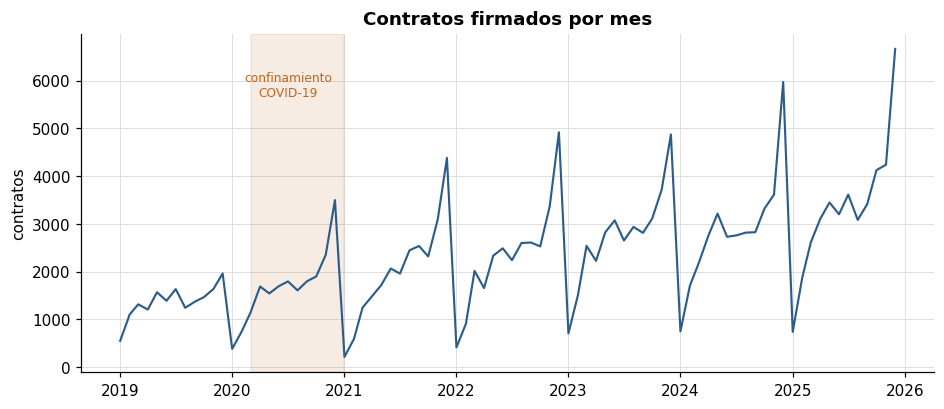

,contratos,crecimiento_%,mediana_valor
fecha_de_firma,,,
2019,16425,NaN,22584160.0
2020,20135,22.6,30478395.0
2021,24043,19.4,30091316.0
2022,28070,16.7,29250000.0
2023,32971,17.5,32479498.0
2024,34634,5.0,36007123.0
2025,40113,15.8,39000000.0


firmados en el último trimestre del año: 37.19 %


In [14]:
anio = df_crudo["fecha_de_firma"].dt.year
vol = df_crudo.groupby(df_crudo["fecha_de_firma"].dt.to_period("M")).size()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(vol.index.to_timestamp(), vol.values, lw=1.4)
ax.set_title("Contratos firmados por mes")
ax.set_ylabel("contratos")
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-12-31"),
           color="#c1651a", alpha=0.12)
ax.annotate("confinamiento\nCOVID-19", xy=(pd.Timestamp("2020-07-01"), vol.max() * 0.85),
            ha="center", fontsize=8, color="#c1651a")
print("figura:", guardar(fig, "e_volumen_mensual"))
plt.show()

por_anio = pd.DataFrame({"contratos": anio.value_counts().sort_index()})
por_anio["crecimiento_%"] = (100 * por_anio["contratos"].pct_change()).round(1)
por_anio["mediana_valor"] = (df_crudo.groupby(anio)["valor_del_contrato"]
                             .median().round(0))
display(por_anio)

# Cierre fiscal: que parte de los contratos se firma en el ultimo trimestre del anio.
ultimo_trimestre = df_crudo["fecha_de_firma"].dt.quarter.eq(4).mean()
print(f"firmados en el último trimestre del año: {100 * ultimo_trimestre:.2f} %")

agrupados en 'Otros' (<1 % cada uno): ['Suspendido', 'Cedido', 'Cancelado', 'Borrador']

figura: reports/figures/e_estado_por_anio.png


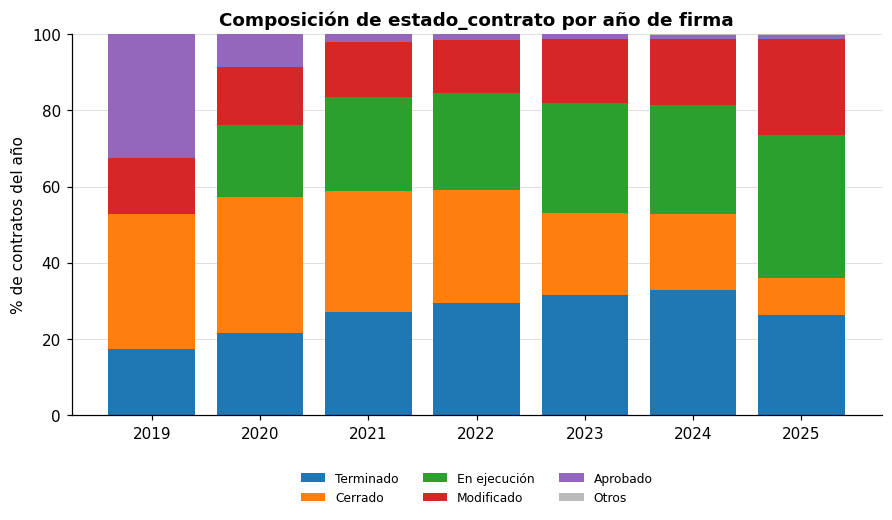

estado_contrato,Terminado,Cerrado,En ejecución,Modificado,Aprobado,Otros
fecha_de_firma,,,,,,
2019,17.3,35.5,0.0,14.7,32.4,0.1
2020,21.5,35.6,19.0,15.3,8.6,0.1
2021,27.0,31.7,24.9,14.4,1.9,0.1
2022,29.4,29.6,25.4,14.0,1.5,0.1
2023,31.4,21.6,29.0,16.6,1.3,0.1
2024,32.9,19.8,28.6,17.4,1.1,0.1
2025,26.3,9.8,37.5,25.1,1.1,0.2



2019 no tiene ni un contrato 'En ejecucion' y concentra 32 % en 'Aprobado';
2025 invierte el patron. La semantica del estado no es estable entre anios.


In [15]:
# estado_contrato por anio de firma: revela que el estado esta rancio.
est = df_crudo["estado_contrato"].str.strip().str.capitalize()

# Los estados marginales se agrupan en "Otros": con 9 categorias el grafico
# necesitaria repetir colores y la leyenda dejaria de ser legible.
share = est.value_counts(normalize=True).mul(100)
marginales = share[share < 1].index.tolist()
est_graf = est.where(~est.isin(marginales), "Otros")
print(f"agrupados en 'Otros' (<1 % cada uno): {marginales}")

comp = pd.crosstab(anio, est_graf, normalize="index").mul(100)
orden = [c for c in comp.sum().sort_values(ascending=False).index if c != "Otros"]
if "Otros" in comp.columns:
    orden.append("Otros")
comp = comp[orden]

paleta = plt.get_cmap("tab10").colors
fig, ax = plt.subplots(figsize=(9.5, 4.5))
abajo = np.zeros(len(comp))
for i, c in enumerate(comp.columns):
    col = "#bbbbbb" if c == "Otros" else paleta[i % 10]
    ax.bar(comp.index.astype(str), comp[c], bottom=abajo, label=c, color=col)
    abajo += comp[c].values
ax.set_ylabel("% de contratos del año")
ax.set_ylim(0, 100)
ax.set_title("Composición de estado_contrato por año de firma")
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
print("figura:", guardar(fig, "e_estado_por_anio"))
plt.show()

display(comp.round(1))
print("\n2019 no tiene ni un contrato 'En ejecucion' y concentra 32 % en 'Aprobado';")
print("2025 invierte el patron. La semantica del estado no es estable entre anios.")

In [16]:
# La prueba de que el estado esta rancio: contratos 'En ejecucion' cuyo plazo ya vencio.
corte = pd.Timestamp(config.FECHA_CORTE)
fn = df_crudo["fecha_de_fin_del_contrato"]
vencido = fn.notna() & (fn < corte)
en_ejec = df_crudo["estado_contrato"].str.strip().str.lower().eq("en ejecución")

print(f"plazo ya vencido (fin < {corte.date()}) : {vencido.sum():,} "
      f"({100*vencido.mean():.2f} % del dataset)")
print(f"marcados 'En ejecucion'                 : {en_ejec.sum():,}")
print(f"  ... de ellos, con plazo YA VENCIDO    : {(en_ejec & vencido).sum():,}")
print()
print("Conclusion: estado_contrato no es un indicador fiable del ciclo de vida.")
print("La observabilidad del desenlace debe decidirse por fecha, no por estado.")

plazo ya vencido (fin < 2026-09-23) : 195,444 (99.52 % del dataset)
marcados 'En ejecucion'                 : 51,441
  ... de ellos, con plazo YA VENCIDO    : 51,238

Conclusion: estado_contrato no es un indicador fiable del ciclo de vida.
La observabilidad del desenlace debe decidirse por fecha, no por estado.


### Anomalías de fecha por periodo

El volumen y el estado ya muestran que los siete años no se registraron igual. Esta parte
revisa las propias fechas y lo que la plataforma registra según el momento de la firma, porque
un cambio en la forma de registrar puede confundirse con un cambio en la ejecución.

Las señales que se usan aquí (adición de plazo, pago sin registrar y desviación) se definen y
justifican en el bloque F. Para que las cifras coincidan con las de los notebooks siguientes,
la celda de abajo aplica los mismos pasos del pipeline del bloque H, solo a las columnas que
hacen falta.

In [17]:
from src.inferencia import prueba_chi2
from src.limpieza import (Bitacora, anular_fechas_implausibles, construir_senales,
                          normalizar_categoricas, sentinelas_a_nan)

# Pasos 2, 3, 4 y 11 del pipeline del bloque H, solo sobre las columnas que usa esta
# seccion. Cada paso anota en una bitacora desechable: la oficial la escribe el bloque H.
COLS_PERIODO = [
    "fecha_de_firma", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato",
    "valor_del_contrato", "valor_pagado", "dias_adicionados", "estado_contrato",
    "liquidaci_n", "nombre_entidad", "modalidad_de_contratacion", "sector", "orden",
    "rama", "entidad_centralizada", "destino_gasto", "tipo_de_contrato",
    "el_contrato_puede_ser_prorrogado",
]
per = df_crudo[COLS_PERIODO].rename(columns=config.RENOMBRES)
for paso in (sentinelas_a_nan, normalizar_categoricas, anular_fechas_implausibles):
    per = paso(per, Bitacora())
valor = per["valor_del_contrato"]
per["pct_ejecucion_financiera"] = np.where(valor > 0, per["valor_pagado"] / valor, np.nan)
per = construir_senales(per, Bitacora())
per["directa"] = per["modalidad_de_contratacion"].str.startswith("Contratación directa")
print(f"desviacion con estas senales: {100 * per['desviacion'].mean():.2f} % "
      "(la misma que reporta el bloque H)")

firma = per["fecha_de_firma"]
inicio = per["fecha_de_inicio_del_contrato"]
fin = per["fecha_de_fin_del_contrato"]
registro = pd.DataFrame({
    "contratos": anio.value_counts().sort_index(),
    "inicio antes de la firma (%)": (100 * (inicio < firma)).groupby(anio).mean(),
    "fin antes de la firma": (fin < firma).groupby(anio).sum(),
    "fin antes del inicio": (fin < inicio).groupby(anio).sum(),
    "contratación directa (%)": (100 * per["directa"]).groupby(anio).mean(),
    "adición de plazo (%)": (100 * per["tiene_adicion"]).groupby(anio).mean(),
    "sin pago registrado (%)": (100 * per["pago_cero"]).groupby(anio).mean(),
}).rename_axis("año de firma")
display(registro.round(1))

raros = (anio == 2025) & (fin < inicio)
print(f"2025, fin antes del inicio: {raros.sum()} contratos, "
      f"{inicio[raros].between('2025-11-01', '2025-12-31').sum()} con inicio en nov-dic de 2025")

# 2019 mes a mes: desde abril casi no hay contratacion directa ni regimen especial.
en_2019 = anio == 2019
grupo = pd.Series(np.select(
    [per["directa"], per["modalidad_de_contratacion"].str.startswith("Contratación régimen")],
    ["contratación directa", "régimen especial"], "resto de modalidades"), index=per.index)
display(pd.crosstab(grupo[en_2019], firma[en_2019].dt.month)
        .loc[["contratación directa", "régimen especial", "resto de modalidades"]]
        .rename_axis(index="2019", columns="mes de firma"))

desviacion con estas senales: 13.55 % (la misma que reporta el bloque H)


,contratos,inicio antes de la firma (%),fin antes de la firma,fin antes del inicio,contratación directa (%),adición de plazo (%),sin pago registrado (%)
año de firma,,,,,,,
2019,16425,60.2,1515,0,1.2,4.2,72.1
2020,20135,15.1,554,0,9.9,7.8,63.8
2021,24043,0.3,151,4,6.0,7.4,59.0
2022,28070,0.1,86,4,4.1,6.7,52.7
2023,32971,0.0,98,1,4.0,7.8,52.5
2024,34634,0.0,77,1,3.8,9.3,47.1
2025,40113,0.0,119,115,3.7,17.3,50.2


2025, fin antes del inicio: 115 contratos, 111 con inicio en nov-dic de 2025


mes de firma,1,2,3,4,5,6,7,8,9,10,11,12
2019,,,,,,,,,,,,
contratación directa,48,72,54,4,2,3,2,2,1,0,0,1
régimen especial,119,166,137,34,16,18,35,4,6,2,3,20
resto de modalidades,381,864,1123,1166,1549,1367,1596,1235,1361,1463,1632,1939


**2019 es otro registro.** El 60,2 % de sus contratos empieza antes de la fecha de firma y
1.515 (9,2 %) terminan antes de ella. En 2020 lo primero baja al 15,1 % y desde 2021 queda por
debajo del 0,3 %. A partir de abril de 2019 la contratación directa pasa de 48–72 contratos al
mes a 0–4, y el régimen especial de 119–166 a 2–35. Además, el 72,1 % de los contratos del año
no tiene pago registrado. Junto con lo que ya mostró el estado (ningún contrato «En ejecución»
y un 32 % en «Aprobado»), todo apunta a que en 2019 la plataforma no recogía la contratación
como después: contratos cargados después de firmados, o una fecha de firma que registra otra
cosa.

**Lo que se registra cambia con los años.** La adición de plazo sube del 4,2 % en 2019 al
17,3 % en 2025, y el pago sin registrar baja del 72,1 % al 47,1 % entre 2019 y 2024. En 2025
aparecen además 115 contratos que terminan antes de empezar (antes eran 4 por año como
máximo), 111 de ellos con inicio en noviembre o diciembre de 2025.

figura: reports/figures/e_registro_por_mes.png


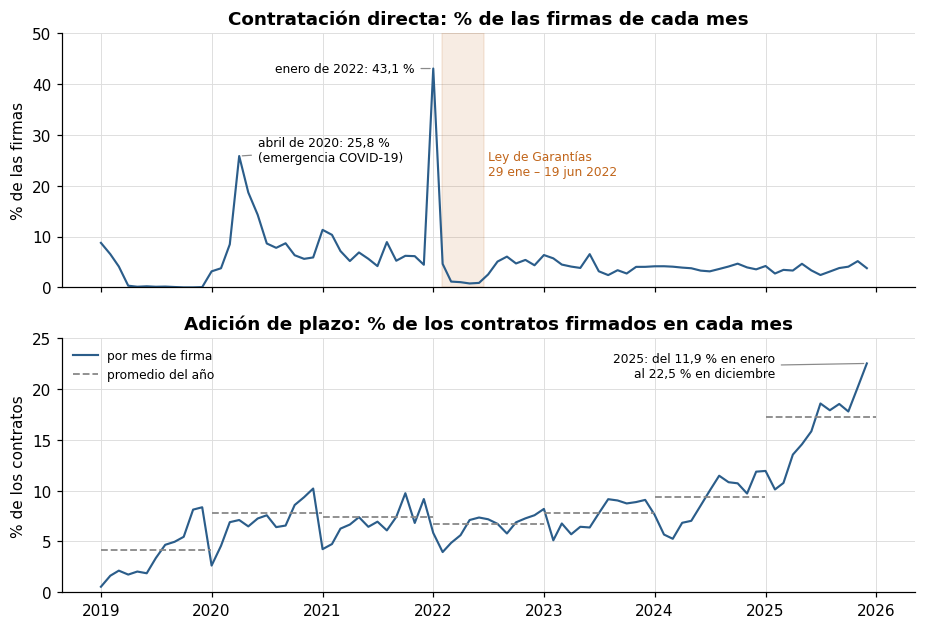

contratacion directa, 1 a 28 de enero de 2022  : 169 de 379 (44.6 %)
                      1 a 28 de enero de 2021  : 21 de 201 (10.4 %)
                      solo el 28 de enero 2022 : 81 de 98 (82.7 %)
                      29 de enero a 19 de junio de 2022: 120 de 8,525 (1.4 %)
                      29 de enero a 19 de junio de 2021: 422 de 6,205 (6.8 %)
contratacion directa en abril, mayo y junio de 2020 (%): [25.8, 18.7, 14.3]
adicion de plazo por mes de 2025 (%): [11.9, 10.1, 10.8, 13.5, 14.6, 15.8, 18.6, 17.9, 18.5, 17.8, 20.2, 22.5]


In [18]:
# Series mensuales. Arriba, que parte de las firmas del mes es contratacion directa;
# abajo, que parte de los contratos firmados ese mes recibio adicion de plazo.
mensual = (per.groupby(firma.dt.to_period("M"))[["directa", "tiene_adicion"]]
           .mean().mul(100))
meses = mensual.index.to_timestamp()
adicion_anual = per.groupby(anio)["tiene_adicion"].mean().mul(100)
flecha = dict(arrowstyle="-", color="#8a8a8a", lw=0.8)

fig, (ax_dir, ax_adic) = plt.subplots(2, 1, figsize=(10, 6.6), sharex=True)
ax_dir.plot(meses, mensual["directa"], lw=1.4)
ax_dir.axvspan(pd.Timestamp("2022-01-29"), pd.Timestamp("2022-06-19"),
               color="#c1651a", alpha=0.12)
ax_dir.annotate("Ley de Garantías\n29 ene – 19 jun 2022",
                xy=(pd.Timestamp("2022-07-01"), 22), ha="left", fontsize=8, color="#c1651a")
for mes, texto, nota, desplaz, lado in [
        ("2020-04", "abril de 2020", "\n(emergencia COVID-19)", (12, 4), "left"),
        ("2022-01", "enero de 2022", "", (-12, 0), "right")]:
    y = mensual.loc[pd.Period(mes, "M"), "directa"]
    ax_dir.annotate(f"{texto}: {y:.1f} %".replace(".", ",") + nota,
                    xy=(pd.Period(mes, "M").to_timestamp(), y), xytext=desplaz,
                    textcoords="offset points", ha=lado, va="center", fontsize=8,
                    arrowprops=flecha)
ax_dir.set_ylim(0, 50)
ax_dir.set_ylabel("% de las firmas")
ax_dir.set_title("Contratación directa: % de las firmas de cada mes")

ax_adic.plot(meses, mensual["tiene_adicion"], lw=1.4, label="por mes de firma")
for k, (a, tasa) in enumerate(adicion_anual.items()):
    ax_adic.hlines(tasa, pd.Timestamp(f"{a}-01-01"), pd.Timestamp(f"{a}-12-31"),
                   color="#8a8a8a", lw=1.2, ls="--",
                   label="promedio del año" if k == 0 else None)
ene_25 = mensual.loc[pd.Period("2025-01", "M"), "tiene_adicion"]
dic_25 = mensual.loc[pd.Period("2025-12", "M"), "tiene_adicion"]
ax_adic.annotate(f"2025: del {ene_25:.1f} % en enero\nal {dic_25:.1f} % en diciembre".replace(".", ","),
                 xy=(pd.Timestamp("2025-12-01"), dic_25), xytext=(-60, -2),
                 textcoords="offset points", ha="right", va="center", fontsize=8,
                 arrowprops=flecha)
ax_adic.set_ylim(0, 25)
ax_adic.set_ylabel("% de los contratos")
ax_adic.set_title("Adición de plazo: % de los contratos firmados en cada mes")
ax_adic.legend(fontsize=8, loc="upper left")
print("figura:", guardar(fig, "e_registro_por_mes"))
plt.show()

def directa_entre(desde, hasta):
    """Contratos directos firmados entre dos fechas, incluidas."""
    m = firma.between(desde, hasta)
    n_dir = int(per.loc[m, "directa"].sum())
    return f"{n_dir:,} de {int(m.sum()):,} ({100 * n_dir / m.sum():.1f} %)"

print("contratacion directa, 1 a 28 de enero de 2022  :", directa_entre("2022-01-01", "2022-01-28"))
print("                      1 a 28 de enero de 2021  :", directa_entre("2021-01-01", "2021-01-28"))
print("                      solo el 28 de enero 2022 :", directa_entre("2022-01-28", "2022-01-28"))
print("                      29 de enero a 19 de junio de 2022:", directa_entre("2022-01-29", "2022-06-19"))
print("                      29 de enero a 19 de junio de 2021:", directa_entre("2021-01-29", "2021-06-19"))
print("contratacion directa en abril, mayo y junio de 2020 (%):",
      mensual.loc["2020-04":"2020-06", "directa"].round(1).tolist())
print("adicion de plazo por mes de 2025 (%):",
      mensual.loc["2025-01":"2025-12", "tiene_adicion"].round(1).tolist())

In [19]:
# ¿El salto de la adicion en 2025 es general o de unas pocas entidades?
dos_anios = per[anio.isin([2024, 2025])].assign(anio_firma=anio)
for col, nombre in [("orden", "orden de la entidad"),
                    ("modalidad_de_contratacion", "modalidad"),
                    ("tipo_de_contrato", "tipo de contrato")]:
    tasas = dos_anios.pivot_table(index=col, columns="anio_firma", values="tiene_adicion",
                                  aggfunc="mean").mul(100)
    n_2025 = dos_anios.loc[dos_anios["anio_firma"] == 2025, col].value_counts()
    tasas = tasas[n_2025.reindex(tasas.index, fill_value=0) >= 500]   # categorias con volumen
    display(tasas.round(1).rename_axis(index=nombre, columns="adición de plazo (%)"))

adic_2025 = per.loc[(anio == 2025) & per["tiene_adicion"], "nombre_entidad"].value_counts()
print(f"adiciones firmadas en 2025: {adic_2025.sum():,}, en {adic_2025.size:,} entidades; "
      f"las 10 que mas adicionan suman el {100 * adic_2025.head(10).sum() / adic_2025.sum():.1f} %")

# ¿Se alargan contratos para cubrir la Ley de Garantias del anio siguiente? Si fuera asi,
# las adiciones firmadas en 2021 y en 2025 terminarian mas a menudo dentro de la ventana de
# restriccion de 2022 y de 2026. Los demas anios usan la misma ventana de calendario.
VENTANA_GARANTIAS = {2022: ("2022-01-29", "2022-06-19"), 2026: ("2026-01-31", "2026-06-21")}
ventanas = []
for a in range(2019, 2026):
    desde, hasta = VENTANA_GARANTIAS.get(a + 1, (f"{a + 1}-01-31", f"{a + 1}-06-21"))
    con_adicion = (anio == a) & per["tiene_adicion"] & fin.notna()
    ventanas.append({
        "año de firma": a,
        "ventana del año siguiente": f"{desde} a {hasta}",
        "Ley de Garantías": "sí" if a + 1 in VENTANA_GARANTIAS else "no",
        "adiciones que terminan dentro (%)":
            round(100 * fin[con_adicion].between(desde, hasta).mean(), 1),
    })
display(pd.DataFrame(ventanas).set_index("año de firma"))

# Calendario: el cierre del anio fiscal y los fines de semana.
en_diciembre = firma.dt.month == 12
fin_de_semana = (firma.dt.dayofweek >= 5).groupby(anio).mean().mul(100)
print(f"firmas en diciembre: {100 * en_diciembre.mean():.1f} % "
      f"(un mes promedio tendria el {100 / 12:.1f} %)")
print(f"firmas en sabado o domingo: {100 * (firma.dt.dayofweek >= 5).mean():.2f} %; "
      f"por anio, entre {fin_de_semana.min():.1f} % y {fin_de_semana.max():.1f} %")

adición de plazo (%),2024,2025
orden de la entidad,,
Nacional,11.0,23.1
Territorial,8.2,13.9


adición de plazo (%),2024,2025
modalidad,,
Contratación directa,7.6,11.0
Contratación directa (con ofertas),10.2,16.9
Contratación régimen especial,6.1,10.6
Contratación régimen especial (con ofertas),26.1,32.7
Mínima cuantía,6.9,13.0
Selección abreviada de menor cuantía,15.1,28.8
Selección abreviada subasta inversa,15.0,30.5


adición de plazo (%),2024,2025
tipo de contrato,,
Compraventa,10.4,19.0
Suministros,8.6,16.0


adiciones firmadas en 2025: 6,934, en 1,328 entidades; las 10 que mas adicionan suman el 11.4 %


,ventana del año siguiente,Ley de Garantías,adiciones que terminan dentro (%)
año de firma,,,
2019,2020-01-31 a 2020-06-21,no,23.9
2020,2021-01-31 a 2021-06-21,no,23.2
2021,2022-01-29 a 2022-06-19,sí,23.9
2022,2023-01-31 a 2023-06-21,no,26.2
2023,2024-01-31 a 2024-06-21,no,21.5
2024,2025-01-31 a 2025-06-21,no,27.6
2025,2026-01-31 a 2026-06-21,sí,28.8


firmas en diciembre: 16.4 % (un mes promedio tendria el 8.3 %)
firmas en sabado o domingo: 1.87 %; por anio, entre 1.4 % y 2.2 %


**Dos cambios de modalidad que responden a la ley, no a errores de registro.** En enero de
2022 la contratación directa salta al 43,1 % de las firmas: del 1 al 28 de enero se firmaron 169
contratos directos (21 en los mismos días de 2021), 81 de ellos el día 28. El 29 de enero empezó
la restricción de la Ley de Garantías (Ley 996 de 2005) por las elecciones presidenciales, y
hasta el 19 de junio la directa cae a 120 de 8.525 firmas (1,4 %, frente al 6,8 % del mismo
tramo de 2021). En abril, mayo y junio de 2020, con la emergencia del COVID-19, la directa sube
al 25,8 %, 18,7 % y 14,3 %.

**El calendario pesa, pero no es una anomalía.** Diciembre concentra el 16,4 % de las firmas,
el doble de un mes promedio: es el cierre del año fiscal. Los fines de semana reciben el 1,9 %
de las firmas, una proporción estable entre años.

**La adición de plazo tiene dos patrones.** Dentro de cada año crece con el mes de firma,
probablemente porque los contratos firmados cerca del cierre cruzan a la vigencia siguiente.
Entre años el nivel sube, y en 2025 salta: del 11,9 % en enero al 22,5 % en diciembre. El salto
es general: la nacional pasa del 11,0 % al 23,1 %, la territorial del 8,2 % al 13,9 %, y suben
todas las modalidades con volumen. No se concentra en pocas entidades: las diez que más
adicionan suman el 11,4 % de las adiciones de 2025. Tampoco lo explica la Ley de Garantías de
2026: el 28,8 % de las adiciones de 2025 termina dentro de la ventana de restricción, casi lo
mismo que en 2024 (27,6 %), y las de 2021 no terminaron más a menudo en la ventana de 2022
(23,9 %). Y no es un efecto del tiempo de exposición, porque los contratos de 2025 son los que
menos tiempo han tenido para recibir una adición. Con estos datos no se puede separar un cambio
en la forma de registrar las modificaciones de un cambio real de comportamiento. En cualquiera
de los dos casos, la adición de 2025 no es comparable con la de los años anteriores.

### Sensibilidad: ¿cambian las asociaciones sin 2019 o sin 2025?

Las dos anomalías que pueden mover los resultados son 2019, porque su registro es distinto, y
2025, porque su adición de plazo salta. La prueba consiste en repetir la matriz exploratoria del
notebook 03 (sección 13) en cuatro ventanas: los siete años, sin 2019, sin 2025 y 2020–2024. La
matriz cruza nueve características con cuatro comportamientos y mide cada par con la V de
Cramér. Una conclusión cambia si algún par cruza el umbral de relevancia (V = 0,10) o si cambia
qué características lo superan.

In [20]:
# Mismas filas, columnas, bandas de valor y muestras que la matriz del notebook 03.
CORTES = [0, 10e6, 50e6, 200e6, 1000e6, np.inf]
ETIQ = ["< 10 M", "10–50 M", "50–200 M", "200–1.000 M", "> 1.000 M"]
per["banda_valor"] = pd.cut(per["valor_del_contrato"], CORTES, labels=ETIQ,
                            right=False).astype(object)
CARACTERISTICAS = {
    "banda_valor": "Valor del contrato",
    "modalidad_de_contratacion": "Modalidad de contratación",
    "sector": "Sector",
    "orden": "Orden de la entidad",
    "rama": "Rama del poder público",
    "entidad_centralizada": "Centralizada o descentralizada",
    "destino_gasto": "Destino del gasto",
    "tipo_de_contrato": "Tipo de contrato",
    "el_contrato_puede_ser_prorrogado": "¿Se puede prorrogar?",
}
# El segundo valor indica si el comportamiento se mide solo con pago registrado y plazo
# vencido (la muestra M_PAGO del notebook 03).
COMPORTAMIENTOS = {
    "tiene_adicion": ("Adición de plazo", False),
    "subejecucion_parcial": ("Subejecución parcial", True),
    "desviacion": ("Desviación (objetivo)", False),
    "pago_cero": ("Sin pago registrado", False),
}
PERIODOS = {
    "Siete años": anio.notna(),
    "Sin 2019": anio != 2019,
    "Sin 2025": anio != 2025,
    "2020–2024": anio.between(2020, 2024),
}

prevalencias, filas_v = [], []
for periodo, en_periodo in PERIODOS.items():
    m_total = per[en_periodo]
    m_pago = m_total[(m_total["pct_ejecucion_financiera"] > 0)
                     & m_total["desenlace_observable"]]
    prevalencias.append({
        "ventana": periodo,
        "contratos": len(m_total),
        "desviación (%)": 100 * m_total["desviacion"].mean(),
        "adición de plazo (%)": 100 * m_total["tiene_adicion"].mean(),
        "subejecución, con pago (%)": 100 * m_pago["subejecucion_parcial"].mean(),
        "sin pago registrado (%)": 100 * m_total["pago_cero"].mean(),
    })
    for y, (nombre_y, con_pago) in COMPORTAMIENTOS.items():
        muestra = m_pago if con_pago else m_total
        for x, nombre_x in CARACTERISTICAS.items():
            filas_v.append({"ventana": periodo, "caracteristica": nombre_x,
                            "comportamiento": nombre_y,
                            "V": prueba_chi2(muestra, x, y)["valor_efecto"]})

display(pd.DataFrame(prevalencias).set_index("ventana").round(2))

sensibilidad = pd.DataFrame(filas_v)
sensibilidad.to_csv(config.TABLAS / "sensibilidad_periodo.csv", index=False, encoding="utf-8")
print("escrito: reports/tablas/sensibilidad_periodo.csv")

tabla_v = sensibilidad.pivot_table(index=["caracteristica", "comportamiento"],
                                   columns="ventana", values="V")[list(PERIODOS)]
umbral = config.V_MINIMA_UTIL
# Cuatro decimales: hay un par en el borde del umbral y con tres se leeria mal.
display(tabla_v[(tabla_v >= umbral).any(axis=1)]
        .sort_values("Siete años", ascending=False).round(4))

base_v = tabla_v["Siete años"]
for periodo in list(PERIODOS)[1:]:
    cambio = (tabla_v[periodo] - base_v).abs()
    cruzan = [f"{c} x {b} ({base_v[(c, b)]:.4f} -> {tabla_v.loc[(c, b), periodo]:.4f})"
              for c, b in tabla_v.index[(tabla_v[periodo] >= umbral) != (base_v >= umbral)]]
    print(f"{periodo:10}: cambio maximo de V {cambio.max():.3f} ({' x '.join(cambio.idxmax())}); "
          f"pares que cruzan 0,10: {', '.join(cruzan) or 'ninguno'}")

# ¿El efecto del valor es un efecto del anio? Dentro de cada anio, la adicion por banda.
gradiente = (per.pivot_table(index="banda_valor", columns=anio, values="tiene_adicion",
                             aggfunc="mean").mul(100).loc[ETIQ])
display(gradiente.round(1).rename_axis(index="valor del contrato",
                                       columns="adición de plazo (%) por año de firma"))

,contratos,desviación (%),adición de plazo (%),"subejecución, con pago (%)",sin pago registrado (%)
ventana,,,,,
Siete años,196391,13.55,9.51,10.59,54.71
Sin 2019,179966,14.05,9.99,10.36,53.13
Sin 2025,156278,11.46,7.51,10.17,55.86
2020–2024,139853,11.86,7.90,9.83,53.96


escrito: reports/tablas/sensibilidad_periodo.csv


ventana                                          Siete años  Sin 2019  Sin 2025  2020–2024
caracteristica            comportamiento                                                  
Tipo de contrato          Subejecución parcial       0.2268    0.2242    0.2261     0.2224
Sector                    Sin pago registrado        0.2221    0.2260    0.2435     0.2504
Valor del contrato        Desviación (objetivo)      0.1941    0.1940    0.1672     0.1657
                          Adición de plazo           0.1902    0.1916    0.1565     0.1567
Modalidad de contratación Sin pago registrado        0.1464    0.1600    0.1484     0.1648
                          Adición de plazo           0.1444    0.1461    0.1265     0.1272
                          Desviación (objetivo)      0.1381    0.1395    0.1241     0.1246
Valor del contrato        Subejecución parcial       0.1267    0.1252    0.1210     0.1186
Destino del gasto         Sin pago registrado        0.1172    0.1204    0.1231     0.1298
Modalidad de contratación Subejecución parcial       0.1063    0.1085    0.1007     0.1034
Sector                    Subejecución parcial       0.0991    0.0999    0.1068     0.1080

Sin 2019  : cambio maximo de V 0.018 (Orden de la entidad x Sin pago registrado); pares que cruzan 0,10: ninguno
Sin 2025  : cambio maximo de V 0.034 (Valor del contrato x Adición de plazo); pares que cruzan 0,10: Sector x Subejecución parcial (0.0991 -> 0.1068)
2020–2024 : cambio maximo de V 0.034 (Valor del contrato x Adición de plazo); pares que cruzan 0,10: Sector x Subejecución parcial (0.0991 -> 0.1080)


adición de plazo (%) por año de firma,2019,2020,2021,2022,2023,2024,2025
valor del contrato,,,,,,,
< 10 M,1.4,4.6,3.4,2.3,2.4,3.5,6.3
10–50 M,3.9,7.3,6.5,5.3,6.0,6.6,11.1
50–200 M,5.3,9.3,8.6,8.8,10.3,11.6,21.8
200–1.000 M,10.1,10.8,11.9,12.5,13.0,16.4,32.4
> 1.000 M,11.6,14.5,19.8,19.0,22.9,27.9,46.0


**Quitar 2019 no cambia nada.** El cambio máximo de V es 0,018 (orden de la entidad frente al
pago sin registrar) y ningún par cruza el umbral. La desviación sube del 13,55 % al 14,05 %,
porque 2019 tenía poca adición registrada.

**Quitar 2025 debilita al valor y a la modalidad, pero no los cambia de lado.** Frente a la
adición de plazo, la V del valor baja de 0,190 a 0,156 y la de la modalidad de 0,144 a 0,126.
Frente a la desviación, de 0,194 a 0,167 y de 0,138 a 0,124. Siguen siendo las únicas
características por encima de 0,10 en la adición y en la desviación, y la ventana 2020–2024 da
prácticamente lo mismo. El único par que cruza el umbral es el sector frente a la subejecución,
que pasa de 0,099 a 0,107: está en el borde con cualquier ventana.

La tabla por año muestra por qué el valor se sostiene: dentro de cada año la adición crece con
el valor sin excepción, del 1,4 % al 11,6 % en 2019 y del 6,3 % al 46,0 % en 2025. Lo que cambia
con los años es la pendiente, no la dirección. 2025 amplifica el efecto del valor, pero no lo
crea.

**Decisión.** Se conservan los siete años, porque ninguna conclusión depende de incluir 2019 o
2025. Quedan dos precauciones. Las variables construidas con las fechas de inicio o de fin no
son comparables en 2019 y 2020. Y como 2025 amplifica el efecto del valor y de la modalidad, el
notebook 03 compara la tasa de cada año con la que anticipa su mezcla de valor y modalidad, y
los criterios de focalización del notebook 04 deben recalcularse por cohorte.

---
## Bloque F — Viabilidad de las señales objetivo

**Este es el bloque que condiciona el resto del taller.** El enunciado define tres formas de
desviación: adición de plazo, presupuesto comprometido no ejecutado, y cierre sin liquidar.
Antes de construir cualquier hipótesis hay que verificar si esas tres cosas son medibles.

El resultado, adelantado: **ninguna de las tres es utilizable en su forma literal.**

,n,pct
exacto 0,107452,54.77
0-25 %,1171,0.60
25-50 %,2089,1.06
50-75 %,3394,1.73
75-90 %,3025,1.54
90-<100 %,27672,14.10
exacto 100 %,51224,26.11
> 100 %,176,0.09


evaluables: 196,203 | sin evaluar (valor <= 0 o nulo): 188
figura: reports/figures/f_ejecucion_financiera.png


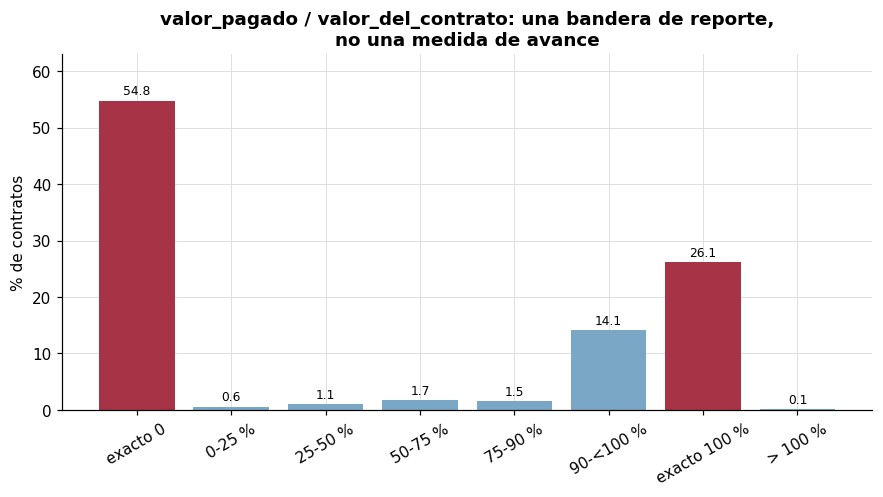

exactamente 0    : 54.77 %
exactamente 100 %: 26.11 %
ejecucion parcial real (0 < pct < 90 %): 4.93 %

La variable es casi binaria: o no se reporto nada, o se reporto el pago
completo. Tratar el cero como subejecucion convertiria un fallo de reporte
en un hallazgo de supervision.


In [21]:
v = df_crudo["valor_del_contrato"]
pct_ej = pd.Series(np.where(v > 0, df_crudo["valor_pagado"] / v, np.nan),
                   index=df_crudo.index)

# Los tramos se construyen con mascaras booleanas explicitas, no con pd.cut:
# las etiquetas "exacto 0" y "exacto 100 %" deben ser literalmente exactas, y
# cualquier borde aproximado (0.9999) las volveria una aproximacion silenciosa.
tramos = {
    "exacto 0":     pct_ej == 0,
    "0-25 %":       (pct_ej > 0) & (pct_ej < 0.25),
    "25-50 %":      (pct_ej >= 0.25) & (pct_ej < 0.50),
    "50-75 %":      (pct_ej >= 0.50) & (pct_ej < 0.75),
    "75-90 %":      (pct_ej >= 0.75) & (pct_ej < 0.90),
    "90-<100 %":    (pct_ej >= 0.90) & (pct_ej < 1.0),
    "exacto 100 %": pct_ej == 1.0,
    "> 100 %":      pct_ej > 1.0,
}
etiq = list(tramos)
n_eval = int(pct_ej.notna().sum())
dist = pd.DataFrame({
    "n": [int(m.sum()) for m in tramos.values()],
}, index=etiq)
dist["pct"] = (100 * dist["n"] / n_eval).round(2)
display(dist)
assert dist["n"].sum() == n_eval, "los tramos deben cubrir todos los casos evaluables"
print(f"evaluables: {n_eval:,} | sin evaluar (valor <= 0 o nulo): {pct_ej.isna().sum():,}")

fig, ax = plt.subplots(figsize=(9.5, 4.2))
colores = ["#a63446" if e in ("exacto 0", "exacto 100 %") else "#7ba7c7" for e in etiq]
ax.bar(etiq, dist["pct"], color=colores)
ax.set_ylabel("% de contratos")
ax.set_title("valor_pagado / valor_del_contrato: una bandera de reporte,\n"
             "no una medida de avance")
ax.tick_params(axis="x", rotation=30)
ax.set_ylim(0, dist["pct"].max() * 1.15)
for i, val in enumerate(dist["pct"]):
    ax.text(i, val + dist["pct"].max() * 0.02, f"{val:.1f}", ha="center", fontsize=8)
print("figura:", guardar(fig, "f_ejecucion_financiera"))
plt.show()

parcial_pct = dist.loc[["0-25 %", "25-50 %", "50-75 %", "75-90 %"], "pct"].sum()
print(f"exactamente 0    : {dist.loc['exacto 0', 'pct']:.2f} %")
print(f"exactamente 100 %: {dist.loc['exacto 100 %', 'pct']:.2f} %")
print(f"ejecucion parcial real (0 < pct < 90 %): {parcial_pct:.2f} %")
print()
print("La variable es casi binaria: o no se reporto nada, o se reporto el pago")
print("completo. Tratar el cero como subejecucion convertiria un fallo de reporte")
print("en un hallazgo de supervision.")

In [22]:
# Senal 1: adicion de plazo. Su relacion con estado_contrato es casi tautologica.
adic = df_crudo["dias_adicionados"] > 0
t = pd.crosstab(est, adic, margins=True)
t.columns = [str(c) for c in t.columns]
t["tasa_adicion_%"] = (100 * t["True"] / t["All"]).round(2)
display(t.sort_values("All", ascending=False))

print(f"De las {adic.sum():,} adiciones, "
      f"{(adic & est.eq('Modificado')).sum():,} "
      f"({100*(adic & est.eq('Modificado')).sum()/adic.sum():.1f} %) "
      "estan en estado 'Modificado'.")
print()
print("Es decir: dias_adicionados > 0 es casi un sinonimo de estado = Modificado.")
print("Consecuencia: estado_contrato NO puede usarse como criterio para anticipar")
print("la adicion de plazo; seria circular.")

,False,True,All,tasa_adicion_%
estado_contrato,,,,
All,177720,18671,196391,9.51
Terminado,53040,1190,54230,2.19
En ejecución,51418,23,51441,0.04
Cerrado,46561,263,46824,0.56
Modificado,17315,17147,34462,49.76
Aprobado,9203,8,9211,0.09
Suspendido,115,38,153,24.84
Cedido,42,1,43,2.33
Cancelado,25,1,26,3.85


De las 18,671 adiciones, 17,147 (91.8 %) estan en estado 'Modificado'.

Es decir: dias_adicionados > 0 es casi un sinonimo de estado = Modificado.
Consecuencia: estado_contrato NO puede usarse como criterio para anticipar
la adicion de plazo; seria circular.


In [23]:
# Prevalencia de las tres senales del enunciado, en su lectura literal.
liq_no = df_crudo["liquidaci_n"].str.strip().str.lower().eq("no")
subej_amplia = (pct_ej < 0.90).fillna(False)
subej_parcial = ((pct_ej > 0) & (pct_ej < 0.90)).fillna(False)

comparacion = pd.DataFrame([
    {"senal": "adición de plazo", "definicion": "dias_adicionados > 0",
     "n": int(adic.sum()), "prevalencia_%": round(100 * adic.mean(), 2),
     "veredicto": "USABLE"},
    {"senal": "presupuesto no ejecutado (literal)", "definicion": "pagado/valor < 90 %",
     "n": int(subej_amplia.sum()), "prevalencia_%": round(100 * subej_amplia.mean(), 2),
     "veredicto": "NO USABLE: domina el pago cero no reportado"},
    {"senal": "presupuesto no ejecutado (estricta)", "definicion": "0 < pagado/valor < 90 %",
     "n": int(subej_parcial.sum()), "prevalencia_%": round(100 * subej_parcial.mean(), 2),
     "veredicto": "USABLE"},
    {"senal": "cierre sin liquidar", "definicion": "liquidación = No",
     "n": int(liq_no.sum()), "prevalencia_%": round(100 * liq_no.mean(), 2),
     "veredicto": "NO USABLE como objetivo: es la norma, no la anomalía"},
])
display(comparacion)

amplia = (adic | subej_amplia | liq_no)
print(f"Compuesto LITERAL (al menos una de las tres): {100*amplia.mean():.2f} %")
print("Un objetivo que se activa en 8 de cada 10 contratos no focaliza nada.")

,senal,definicion,n,prevalencia_%,veredicto
0,adición de plazo,dias_adicionados > 0,18671,9.51,USABLE
1,presupuesto no ejecutado (literal),pagado/valor < 90 %,117131,59.64,NO USABLE: domina el pago cero no reportado
2,presupuesto no ejecutado (estricta),0 < pagado/valor < 90 %,9679,4.93,USABLE
3,cierre sin liquidar,liquidación = No,118418,60.30,"NO USABLE como objetivo: es la norma, no la an..."


Compuesto LITERAL (al menos una de las tres): 83.77 %
Un objetivo que se activa en 8 de cada 10 contratos no focaliza nada.


In [24]:
# Solapamiento entre las tres senales (version estricta de la financiera).
S = pd.DataFrame({"adición": adic, "subejec_parcial": subej_parcial,
                  "sin_liquidar": liq_no})
patron = S.astype(int).astype(str).agg("".join, axis=1)
solap = patron.value_counts().rename_axis("adic|subej|sinliq").reset_index(name="n")
solap["pct"] = (100 * solap["n"] / len(S)).round(2)
display(solap)

from scipy.stats import chi2_contingency
print("Asociacion entre pares de senales (phi de Matthews):")
for a, b in [("adición", "subejec_parcial"), ("adición", "sin_liquidar"),
             ("subejec_parcial", "sin_liquidar")]:
    tab = pd.crosstab(S[a], S[b])
    chi2 = chi2_contingency(tab)[0]
    phi = np.sqrt(chi2 / len(S))
    print(f"  {a:16} vs {b:16} phi = {phi:.4f}")
print()
print("Las asociaciones son debiles: las senales miden fenomenos distintos, asi que")
print("tiene sentido analizarlas por separado y no colapsarlas en un solo indice.")

,adic|subej|sinliq,n,pct
0,001,103786,52.85
1,000,65939,33.58
2,101,9792,4.99
3,100,7195,3.66
4,011,4163,2.12
5,010,3832,1.95
6,110,1007,0.51
7,111,677,0.34


Asociacion entre pares de senales (phi de Matthews):
  adición          vs subejec_parcial  phi = 0.0612
  adición          vs sin_liquidar     phi = 0.0280
  subejec_parcial  vs sin_liquidar     phi = 0.0479

Las asociaciones son debiles: las senales miden fenomenos distintos, asi que
tiene sentido analizarlas por separado y no colapsarlas en un solo indice.


### Veredicto del bloque F

| Señal del enunciado | Veredicto | Razón |
|---|---|---|
| Adición de plazo | **Usable** (9,51 %) | Evento contractual objetivo y registrado. Pero es casi sinónimo de `estado = Modificado`, que por tanto no puede usarse como criterio para anticiparla. |
| Presupuesto no ejecutado | **Usable solo en versión estricta** (4,93 %) | `valor_pagado` es casi binario: 54,8 % exactamente en cero y 26,1 % exactamente en 100 %, con otro 14,1 % entre el 90 % y el 100 %. El cero mezcla incumplimiento con falta de reporte, y no hay forma de separarlos. Se restringe a la ejecución parcial real, y solo donde el plazo ya venció (4,76 %): un contrato en curso con el 40 % pagado no está subejecutado, no ha terminado. |
| Cierre sin liquidar | **No usable como objetivo** (60,30 %) | Se activa en 6 de cada 10 contratos: es el comportamiento administrativo normal. Se conserva como variable descriptiva. |

**Decisión.** La variable objetivo del taller queda definida como:

```
desviacion = (dias_adicionados > 0)
             OR (0 < valor_pagado/valor_del_contrato < 0,90  Y  plazo vencido)
```

con prevalencia del **13,55 %**, que sí permite focalizar supervisión. La versión de tres
señales se conserva en `n_senales` (0–3) para medir severidad, y `desviacion_severa`
(`n_senales >= 2`, 7,84 %) queda disponible como objetivo alternativo más exigente.

**Limitación que hay que declarar en el informe final:** los 107.452 contratos con pago
cero (54,7 % del universo) son una zona ciega. Puede contener incumplimiento real que este análisis no detecta.

---
## Bloque G — Top 5 atributos: análisis univariado

Los cinco atributos se eligen por su papel en la decisión de supervisión que el punto 4 debe
recomendar: **valor del contrato, modalidad de contratación, destino del gasto, sector** y
**días adicionados**.

valor_del_contrato (COP corrientes)
  n validos    : 196,391
  media        : 65,824,255,028   <- inutil: la arrastra un solo contrato
  mediana      : 33,600,000
  p99          : 4,118,481,943
  maximo       : 12,858,450,316,000,000
  asimetria    : 443.2

Contrato dominante: CO1.PCCNTR.3102623
  entidad    : INSTITUTO MUNICIPAL DEL DEPORTE Y LA RECREACION DE YUMBO
  valor      : 12,858,450,316,000,000 COP
  = 99.47 % de la suma total y 8.04 veces el PIB


figura: reports/figures/g_valor_contrato.png


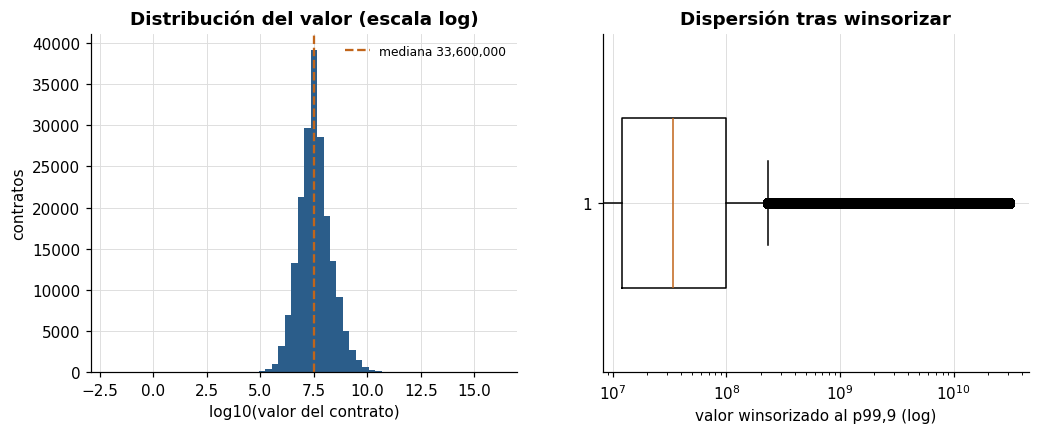

In [25]:
# --- G1. valor_del_contrato --------------------------------------------------
v = df_crudo["valor_del_contrato"]
print("valor_del_contrato (COP corrientes)")
print(f"  n validos    : {v.notna().sum():,}")
print(f"  media        : {v.mean():,.0f}   <- inutil: la arrastra un solo contrato")
print(f"  mediana      : {v.median():,.0f}")
print(f"  p99          : {v.quantile(0.99):,.0f}")
print(f"  maximo       : {v.max():,.0f}")
print(f"  asimetria    : {v.skew():,.1f}")

dom = perfil["outliers"]["_dominante"]
print(f"\nContrato dominante: {dom['id_contrato']}")
print(f"  entidad    : {dom['entidad']}")
print(f"  valor      : {dom['valor']:,.0f} COP")
print(f"  = {dom['pct_del_total']:.2f} % de la suma total y {dom['veces_el_pib']} veces el PIB")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
lv = np.log10(v[v > 0])
a1.hist(lv, bins=60, color="#2b5d8a")
a1.set_xlabel("log10(valor del contrato)")
a1.set_ylabel("contratos")
a1.set_title("Distribución del valor (escala log)")
a1.axvline(np.log10(v.median()), color="#c1651a", ls="--", lw=1.5,
           label=f"mediana {v.median():,.0f}")
a1.legend(fontsize=8)

vw = v.clip(upper=v.quantile(0.999))
a2.boxplot(vw.dropna(), vert=False, widths=0.5)
a2.set_xscale("log")
a2.set_xlabel("valor winsorizado al p99,9 (log)")
a2.set_title("Dispersión tras winsorizar")
print("figura:", guardar(fig, "g_valor_contrato"))
plt.show()

modalidad_de_contratacion    centinelas:      0 ( 0.00 %)


destino_gasto                centinelas:    911 ( 0.46 %)


sector                       centinelas: 24,474 (12.46 %)


figura: reports/figures/g_categoricas_top5.png


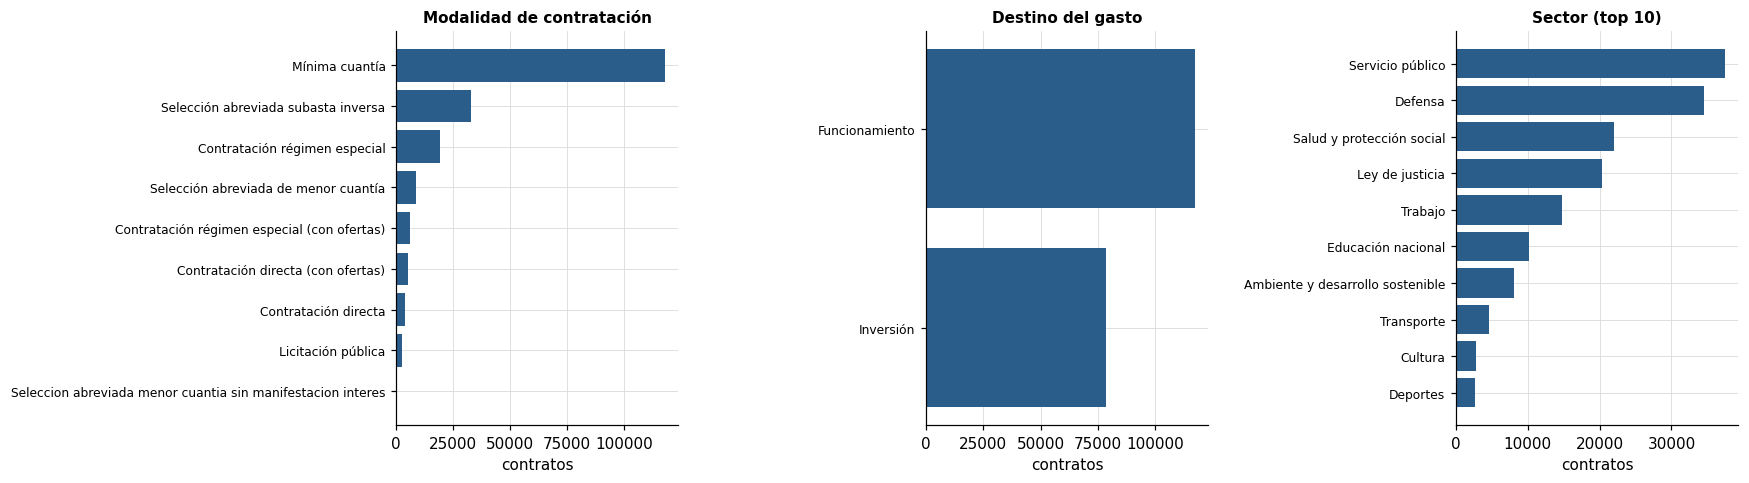


modalidad_de_contratacion: 9 categorias validas | moda 'Mínima cuantía' = 60.0 % | top3 = 86.5 %

destino_gasto: 2 categorias validas | moda 'Funcionamiento' = 59.9 % | top3 = 100.0 %

sector: 24 categorias validas | moda 'Servicio público' = 21.7 % | top3 = 54.7 %


In [26]:
# --- G2 a G4. Categoricas clave ---------------------------------------------
from src.utiles import norm_txt

CATS = ["modalidad_de_contratacion", "destino_gasto", "sector"]
TITULOS = ["Modalidad de contratación", "Destino del gasto", "Sector (top 10)"]

# Se enmascaran los centinelas antes de graficar. Sin esto, 'No aplica/no
# pertenece' aparece como la tercera categoria de sector, que es un artefacto
# de captura y no un sector del Estado.
limpias = {}
for col in CATS:
    s = df_crudo[col].str.strip().str.capitalize()
    centinela = s.map(norm_txt).isin(config.SENTINELAS)
    print(f"{col:28} centinelas: {centinela.sum():>6,} ({100*centinela.mean():5.2f} %)")
    limpias[col] = s.where(~centinela)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, titulo in zip(axes, CATS, TITULOS):
    s = limpias[col].value_counts().head(10)
    ax.barh(s.index.astype(str)[::-1], s.values[::-1], color="#2b5d8a")
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel("contratos")
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
print("figura:", guardar(fig, "g_categoricas_top5"))
plt.show()

for col in CATS:
    s = limpias[col].dropna()
    vc = s.value_counts()
    print(f"\n{col}: {vc.size} categorias validas | "
          f"moda '{vc.index[0]}' = {100*vc.iloc[0]/len(s):.1f} % | "
          f"top3 = {100*vc.head(3).sum()/len(s):.1f} %")

In [27]:
# El catalogo de modalidades merece inspeccion literal: la capitalizacion es
# inconsistente entre categorias de la misma familia, y conviene descartar que
# alguna etiqueta sea un duplicado encubierto de otra.
mod = df_crudo["modalidad_de_contratacion"].str.strip()
vc = mod.value_counts()
print("Catalogo completo de modalidad_de_contratacion:\n")
for etiqueta, n in vc.items():
    print(f"  {n:>7,}  ({100*n/len(mod):5.2f} %)  {etiqueta}")

clave = vc.index.to_series().map(lambda s: norm_txt(s).replace(" de ", " ").replace(" ", ""))
dups = clave.groupby(clave).size()
dups = dups[dups > 1]
print(f"\nEtiquetas que colapsan al normalizar tildes, mayusculas y enlaces: {len(dups)}")
print("No hay duplicados encubiertos: las 9 categorias son modalidades distintas.")
print("En particular, 'Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes'")
print("NO es una variante de 'Seleccion Abreviada de Menor Cuantia': es otra figura.")

raras = vc[vc / len(mod) < 0.01]
print(f"\nCategorias con menos del 1 % de los contratos: {len(raras)}")
display(raras.to_frame("contratos"))
print("Relevante para el notebook 03: una categoria de 236 registros produce")
print("frecuencias esperadas bajas en tablas de contingencia y puede invalidar el")
print("supuesto de la prueba chi-cuadrado. Habra que agruparla o excluirla.")

Catalogo completo de modalidad_de_contratacion:

  117,753  (59.96 %)  Mínima cuantía
   32,907  (16.76 %)  Selección abreviada subasta inversa
   19,250  ( 9.80 %)  Contratación régimen especial
    8,822  ( 4.49 %)  Selección Abreviada de Menor Cuantía
    6,154  ( 3.13 %)  Contratación régimen especial (con ofertas)
    5,001  ( 2.55 %)  Contratación Directa (con ofertas)
    3,938  ( 2.01 %)  Contratación directa
    2,330  ( 1.19 %)  Licitación pública
      236  ( 0.12 %)  Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes

Etiquetas que colapsan al normalizar tildes, mayusculas y enlaces: 0
No hay duplicados encubiertos: las 9 categorias son modalidades distintas.
En particular, 'Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes'
NO es una variante de 'Seleccion Abreviada de Menor Cuantia': es otra figura.

Categorias con menos del 1 % de los contratos: 1


,contratos
modalidad_de_contratacion,
Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes,236


Relevante para el notebook 03: una categoria de 236 registros produce
frecuencias esperadas bajas en tablas de contingencia y puede invalidar el
supuesto de la prueba chi-cuadrado. Habra que agruparla o excluirla.


dias_adicionados
  ceros        : 177,720 (90.49 %)
  positivos    : 18,671 (9.51 %)
  maximo       : 14,276 dias (= 39.1 anios)

Entre los positivos:


,dias
count,18671.0
mean,53.7
std,121.6
min,1.0
25%,15.0
50%,31.0
75%,62.0
90%,122.0
99%,322.6
max,14276.0


figura:

 reports/figures/g_dias_adicionados.png


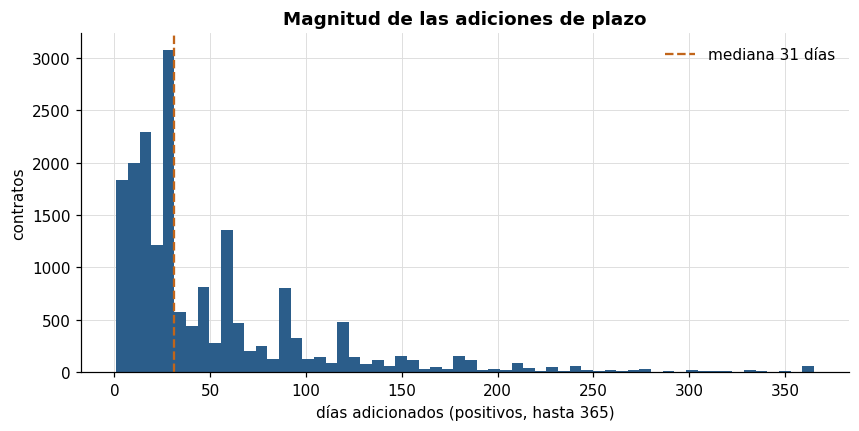


La mediana de 31 dias equivale a un mes de retraso: no es
una prorroga marginal, sino un desfase material en la entrega del bien.


In [28]:
# --- G5. dias_adicionados ----------------------------------------------------
d = df_crudo["dias_adicionados"]
print("dias_adicionados")
print(f"  ceros        : {(d == 0).sum():,} ({100*(d == 0).mean():.2f} %)")
print(f"  positivos    : {(d > 0).sum():,} ({100*(d > 0).mean():.2f} %)")
print(f"  maximo       : {d.max():,} dias (= {d.max()/365:.1f} anios)")
print("\nEntre los positivos:")
display(d[d > 0].describe(percentiles=[.25, .5, .75, .9, .99]).round(1).to_frame("dias"))

fig, ax = plt.subplots(figsize=(9, 4))
pos = d[(d > 0) & (d <= 365)]
ax.hist(pos, bins=60, color="#2b5d8a")
ax.set_xlabel("días adicionados (positivos, hasta 365)")
ax.set_ylabel("contratos")
ax.set_title("Magnitud de las adiciones de plazo")
ax.axvline(pos.median(), color="#c1651a", ls="--", lw=1.5,
           label=f"mediana {pos.median():.0f} días")
ax.legend()
print("figura:", guardar(fig, "g_dias_adicionados"))
plt.show()

print(f"\nLa mediana de {pos.median():.0f} dias equivale a un mes de retraso: no es")
print("una prorroga marginal, sino un desfase material en la entrega del bien.")

---
## Bloque H — Pipeline de tratamiento y bitácora de decisiones

El pipeline aplica once pasos en orden. Dos principios lo gobiernan:

1. **Marcar antes que borrar.** Ninguna fila se elimina. Los registros problemáticos quedan
   señalados con banderas y las columnas originales se conservan junto a las derivadas.
2. **Bitácora auditable.** Cada paso registra el problema, la decisión, su justificación y
   cuántas filas afectó.

In [29]:
df, bitacora = limpiar(df_crudo)
bitacora.to_csv(config.TABLAS / "bitacora_tratamiento.csv", index=False, encoding="utf-8")
print(f"\nescrito: reports/tablas/bitacora_tratamiento.csv")
bitacora[["paso", "filas_afectadas", "pct_filas"]]

  1  renombrando columnas ...


  2  centinelas a NaN ...


  3  normalizando categoricas ...


  4  anulando fechas implausibles ...


  5  derivando duracion ...

  6  normalizando proveedor ...


... (4 outputs left out)

  11 construyendo senales objetivo ...


  limpieza lista: 196,391 x 36  ->  196,391 x 70 (+34 derivadas, 0 filas eliminadas)



escrito: reports/tablas/bitacora_tratamiento.csv


,paso,filas_afectadas,pct_filas
0,1. Nombres de columna,4,11.1111
1,2. Centinelas de nulo,206821,2.9253
2,3. Grafia de categoricas,442619,6.2605
3,4. Fechas imposibles,20,0.0102
4,5. Duracion textual,20918,10.6512
5,6. Identidad del proveedor,1671,0.8509
6,7. URL del proceso,29,0.0148
7,8. Clasificador UNSPSC,4779,2.4334
8,9. Concentracion monetaria,197,0.1003
9,10. Bandera de calidad,13595,6.9224


In [30]:
# La bitacora completa: problema -> decision -> justificacion.
for _, r in bitacora.iterrows():
    print("=" * 78)
    print(f"{r['paso']}   ({r['filas_afectadas']:,} filas · {r['pct_filas']} %)")
    print(f"  PROBLEMA      : {r['problema']}")
    print(f"  DECISION      : {r['decision']}")
    print(f"  JUSTIFICACION : {r['justificacion']}")

1. Nombres de columna   (4 filas · 11.1111 %)
  PROBLEMA      : Cuatro columnas perdieron la tilde en la extraccion y quedaron con un guion bajo en su lugar (duraci_n_del_contrato, g_nero_..., liquidaci_n, obligaci_n_ambiental).
  DECISION      : Renombrar las 4 columnas afectadas a su forma sin tilde.
  JUSTIFICACION : Un nombre con guion bajo en mitad de la palabra es ilegible y propenso a errores de tipeo. No afecta ningun dato, solo la cabecera.
2. Centinelas de nulo   (206,821 filas · 2.9253 %)
  PROBLEMA      : 34 de 36 columnas reportaban cero nulos, pero los faltantes venian codificados como texto: No Definido, No aplica, UNSPECIFIED, xxxx.
  DECISION      : Sustituir por NaN el catalogo de 25 centinelas en 15 columnas (206,821 celdas).
  JUSTIFICACION : Sin esto isna() reporta una completitud aparente del 99,97 % frente a una efectiva del 97,04 %: todo conteo de faltantes o imputacion posterior partiria de una premisa falsa.
3. Grafia de categoricas   (442,619 filas · 6.2605 %

In [31]:
# Verificacion del resultado del pipeline.
print(f"dimension final : {df.shape[0]:,} x {df.shape[1]} "
      f"(+{df.shape[1] - df_crudo.shape[1]} columnas derivadas)")
print(f"filas eliminadas: {df_crudo.shape[0] - df.shape[0]}")

senales = ["plazo_vencido", "tiene_adicion", "pago_cero", "subejecucion_parcial",
           "sin_liquidar", "desviacion", "desviacion_severa"]
res = pd.DataFrame({
    "n": [int(df[c].fillna(False).sum()) for c in senales],
}, index=senales)
res["prevalencia_%"] = (100 * res["n"] / len(df)).round(2)
display(res)

print("\nDistribucion de n_senales (0 a 3):")
t = df["n_senales"].value_counts().sort_index()
display(pd.DataFrame({"n": t, "pct": (100 * t / len(df)).round(2)}))

dimension final : 196,391 x 70 (+34 columnas derivadas)
filas eliminadas: 0


,n,prevalencia_%
plazo_vencido,195443,99.52
tiene_adicion,18671,9.51
pago_cero,107452,54.71
subejecucion_parcial,9355,4.76
sin_liquidar,118418,60.30
desviacion,26603,13.55
desviacion_severa,15400,7.84



Distribucion de n_senales (0 a 3):


,n,pct
n_senales,,
0,65980,33.60
1,115011,58.56
2,14767,7.52
3,633,0.32


,contratos,tasa_%
modalidad_de_contratacion,,
Licitación pública,2330,34.25
Contratación régimen especial (con ofertas),6154,21.25
Selección abreviada subasta inversa,32907,20.55
Selección abreviada de menor cuantía,8822,19.51
Contratación directa (con ofertas),5001,12.52
Contratación directa,3938,11.63
Mínima cuantía,117753,10.91
Contratación régimen especial,19250,10.46


figura:

 reports/figures/h_desviacion_por_modalidad.png


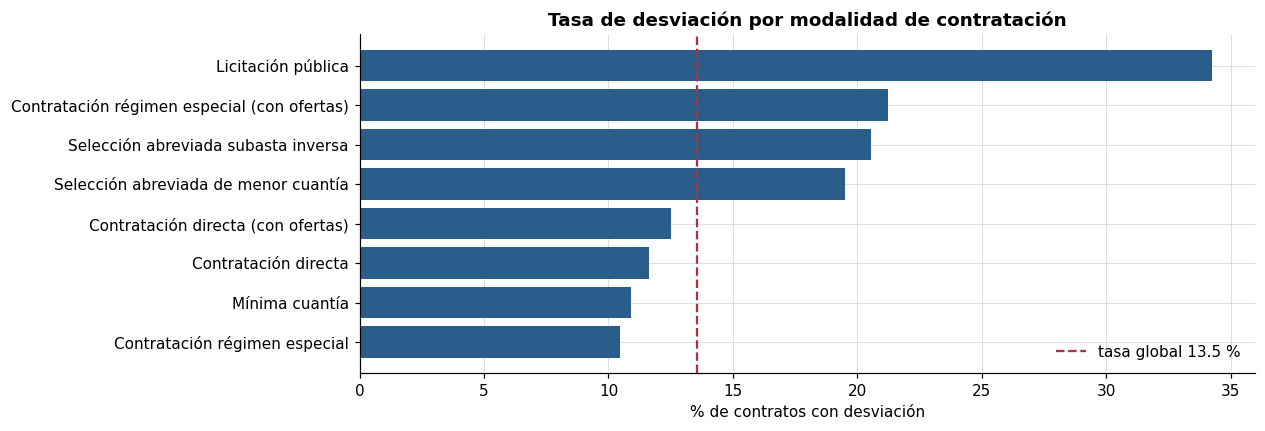

Licitacion publica triplica la tasa de Minima cuantia. El notebook 03 contrasta
formalmente si esa diferencia es significativa y de que tamano es el efecto.


In [32]:
# Primer cruce: la tasa de desviacion ya discrimina por modalidad.
g = (df.groupby("modalidad_de_contratacion")
       .agg(contratos=("desviacion", "size"), tasa=("desviacion", "mean"))
       .query("contratos >= 1000")
       .sort_values("tasa", ascending=False))
g["tasa_%"] = (100 * g["tasa"]).round(2)
display(g[["contratos", "tasa_%"]])

fig, ax = plt.subplots(figsize=(10.5, 4))
ax.barh(g.index.astype(str)[::-1], g["tasa_%"][::-1], color="#2b5d8a")
ax.axvline(100 * df["desviacion"].mean(), color="#a63446", ls="--", lw=1.5,
           label=f"tasa global {100*df['desviacion'].mean():.1f} %")
ax.set_xlabel("% de contratos con desviación")
ax.set_title("Tasa de desviación por modalidad de contratación")
ax.legend()
print("figura:", guardar(fig, "h_desviacion_por_modalidad"))
plt.show()

print("Licitacion publica triplica la tasa de Minima cuantia. El notebook 03 contrasta")
print("formalmente si esa diferencia es significativa y de que tamano es el efecto.")

---
## Bloque I — Artefactos generados

Se guarda el dataset tratado, del que dependen los notebooks siguientes.

In [33]:
df.to_parquet(config.PARQUET_LIMPIO, index=False)
print(f"escrito: data/processed/{config.PARQUET_LIMPIO.name} "
      f"({config.PARQUET_LIMPIO.stat().st_size / 1024**2:.1f} MB)")

print("\nTablas en reports/tablas/:")
for p in sorted(config.TABLAS.glob("*.csv")):
    print(f"  {p.name:34} {p.stat().st_size / 1024:>7.1f} KB")

print("\nFiguras en reports/figures/:")
for p in sorted(config.FIGURAS.glob("*.png")):
    print(f"  {p.name:34} {p.stat().st_size / 1024:>7.1f} KB")

escrito: data/processed/contratos_limpio.parquet (41.4 MB)

Tablas en reports/tablas/:
  bitacora_tratamiento.csv               5.5 KB
  chequeos_integridad.csv                1.7 KB
  cobertura_focalizacion.csv             0.5 KB
  combinaciones_riesgo.csv               3.6 KB
  control_composicion.csv                2.2 KB
  control_destino_por_valor.csv          1.0 KB
  frente_calidad_reporte.csv             0.8 KB
  matriz_asociacion.csv                  4.3 KB
  perfilado_columnas.csv                 3.6 KB
  pruebas_hipotesis.csv                  1.5 KB
  pruebas_robustez.csv                   0.5 KB
  sensibilidad_periodo.csv              10.3 KB
  umbrales_focalizacion.csv              0.4 KB
  validacion_supuestos.csv               1.5 KB

Figuras en reports/figures/:
  c_reglas_integridad.png              140.2 KB
  control_destino_por_valor.png         64.7 KB
  d_completitud_aparente_vs_efectiva.png    78.7 KB
  e_estado_por_anio.png                 35.4 KB
  e_registro_po

---
## Síntesis

**Dimensiones.** 196.391 contratos × 36 columnas. Solo 5 variables numéricas y 3 de fecha;
las 28 restantes son categóricas, lo que orienta la estrategia hacia tablas de contingencia
y pruebas sobre proporciones más que hacia correlaciones continuas.

**Los cuatro problemas de calidad que más condicionan el análisis:**

1. **Completitud falsa.** 34 de 36 columnas declaran cero nulos, pero 206.821 celdas son
   centinelas de texto. La completitud efectiva es 97,04 %, no 99,97 %.
2. **Concentración monetaria extrema.** Un solo contrato concentra el 99,47 % de la suma de
   `valor_del_contrato`, equivalente a 8 veces el PIB de Colombia. Toda media o suma cruda
   es inservible; se trabaja con mediana y con el valor winsorizado.
3. **Fechas imposibles.** `fecha_de_fin_del_contrato` va del año 202 d.C. hasta 2065 sin
   declarar un solo nulo. `fecha_de_firma` es el único eje temporal confiable.
4. **`estado_contrato` está rancio.** 51.238 contratos siguen marcados «En ejecución» aunque
   su plazo ya venció, de modo que la observabilidad del desenlace debe decidirse por fecha.

**Sobre el periodo de análisis.** El 99,52 % de los contratos ya tiene el plazo vencido, así
que la censura por ejecución en curso no es el problema que cabría esperar. Los riesgos
reales son otros: el volumen crece 144 % entre 2019 y 2025, la composición de
`estado_contrato` cambia drásticamente por año, y los valores están en pesos corrientes sin
deflactar. Además, 2019 es otro registro (el 60,2 % de sus contratos empieza antes de la firma)
y la adición de plazo registrada salta en 2025 (17,3 %, frente al 9,3 % de 2024). La
sensibilidad del bloque E muestra que ninguna conclusión depende de esos dos años: sin 2019
ningún par de la matriz de asociación cruza el umbral de 0,10, y sin 2025 el valor y la
modalidad pierden fuerza pero siguen por encima. Por eso no se recorta la ventana: se conservan
los siete años y el notebook 03 compara la tasa de cada año con la que anticipa su
composición.

**Redefinición de la variable objetivo.** Ninguna de las tres desviaciones del enunciado es
utilizable en su forma literal (bloque F). El objetivo queda como adición de plazo **o**
subejecución parcial real —evaluada solo donde el plazo ya venció—, con prevalencia del
13,55 %.

**Insumo para el notebook 02.** `estado_contrato`, `valor_pagado`, `dias_adicionados`,
`liquidacion` y `fecha_de_fin_del_contrato` solo se conocen *después* del hecho. Como el
negocio necesita decidir a quién supervisar **desde la firma**, los criterios de
focalización deben usar exclusivamente variables disponibles en ese momento: valor, modalidad, sector,
orden, destino del gasto, tipo de contrato, categoría UNSPSC y atributos del proveedor.